<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 First Stage Landing Prediction**


 ## Hands-on Lab: Complete the EDA with Visualization


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage. 

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans. 


  ## Objectives
Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

- Exploratory Data Analysis
- Preparing Data  Feature Engineering 


----


Install the below libraries


In [1]:
# Si faltan dependencias, descomenta y ejecuta esta línea:
# %pip install pandas numpy seaborn matplotlib

### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab 



In [2]:
# andas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")


## Exploratory Data Analysis 


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [3]:
df=pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv")

# If you were unable to complete the previous lab correctly you can uncomment and load this csv

# df = pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/dataset_part_2.csv')

df.head(5)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass is also important; it seems the more massive the payload, the less likely the first stage will return.


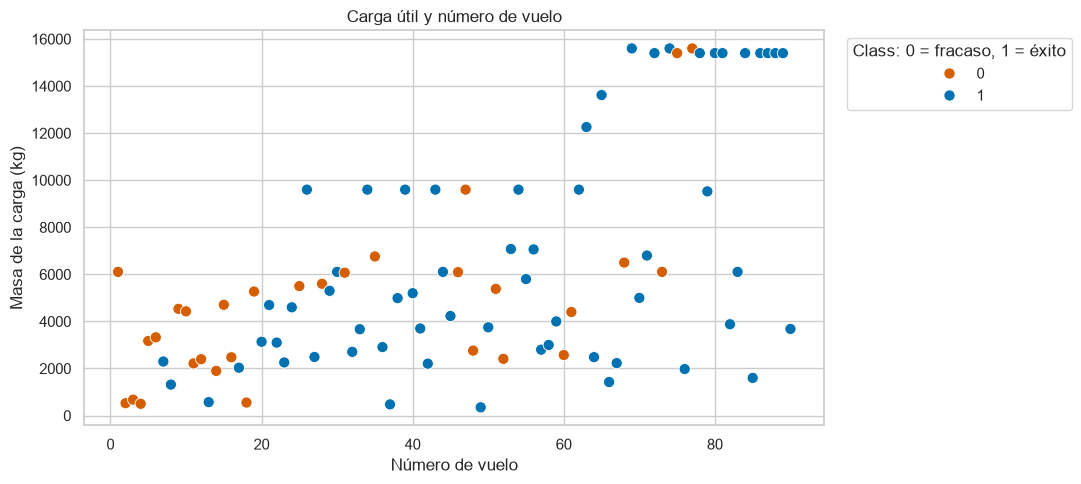

In [4]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x="FlightNumber", y="PayloadMass", hue="Class",
                palette={0: "#D55E00", 1: "#0072B2"}, s=65)
plt.xlabel("Número de vuelo")
plt.ylabel("Masa de la carga (kg)")
plt.title("Carga útil y número de vuelo")
plt.legend(title="Class: 0 = fracaso, 1 = éxito", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>


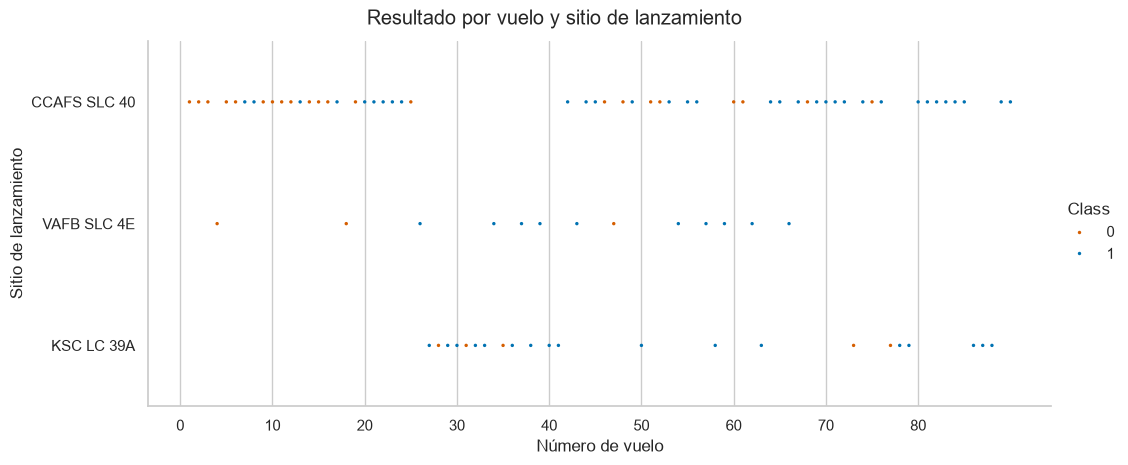

In [17]:
g = sns.catplot(data=df, x="FlightNumber", y="LaunchSite", hue="Class",
                kind="strip", native_scale=True, jitter=False, height=4.5, aspect=2.4,
                palette={0: "#D55E00", 1: "#0072B2"}, s=6)
g.set_axis_labels("Número de vuelo", "Sitio de lanzamiento")
g.ax.set_xticks(range(0, len(df), 10))
g.fig.suptitle("Resultado por vuelo y sitio de lanzamiento", y=1.03)
plt.show()

Now try to explain the patterns you found in the Flight Number vs. Launch Site scatter point plots.


**Análisis:** Los éxitos son más frecuentes en los vuelos posteriores. CCAFS SLC 40 concentra 55 vuelos y tiene un 60 % de éxito; KSC LC 39A alcanza un 77,3 % en 22 vuelos y VAFB SLC 4E un 76,9 % en 13. Son asociaciones descriptivas: los sitios operaron con diferentes misiones y en distintos períodos.

### TASK 2: Visualize the relationship between Payload and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


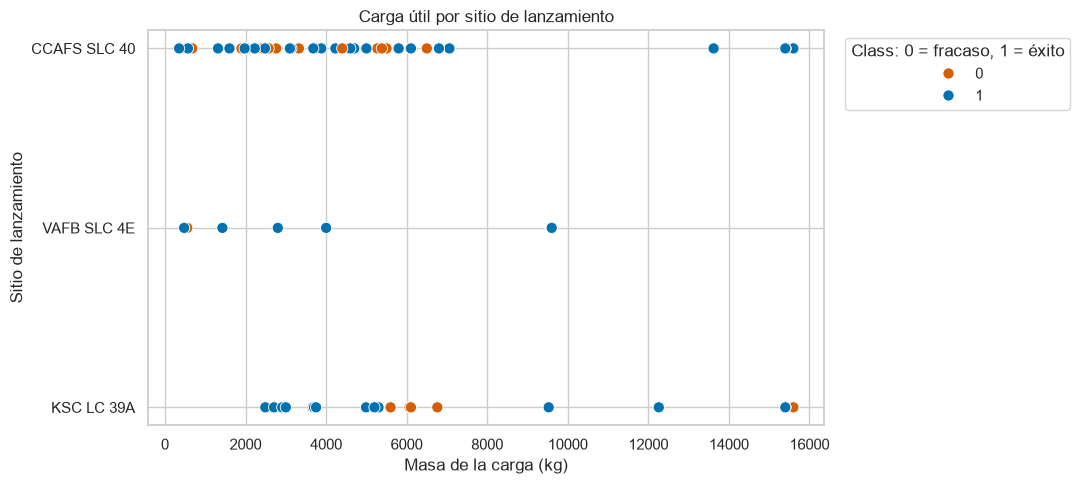

In [6]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x="PayloadMass", y="LaunchSite", hue="Class",
                palette={0: "#D55E00", 1: "#0072B2"}, s=65)
plt.xlabel("Masa de la carga (kg)")
plt.ylabel("Sitio de lanzamiento")
plt.title("Carga útil por sitio de lanzamiento")
plt.legend(title="Class: 0 = fracaso, 1 = éxito", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Análisis:** VAFB SLC 4E no presenta cargas superiores a 10.000 kg en esta muestra. En los otros sitios hay cargas más pesadas. El peso por sí solo no separa todos los aterrizajes exitosos de los fallidos.

### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


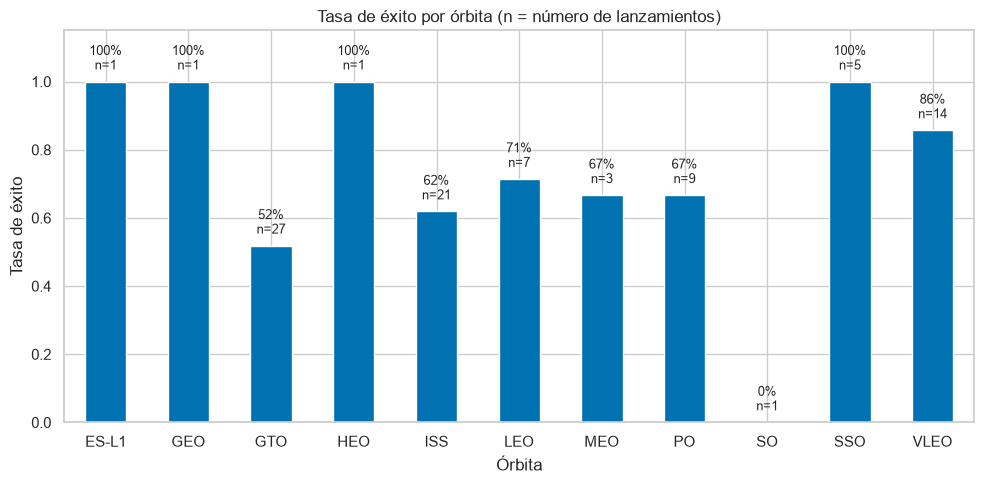

,success_rate,launches
Orbit,,
ES-L1,1.000000,1
GEO,1.000000,1
GTO,0.518519,27
HEO,1.000000,1
ISS,0.619048,21
LEO,0.714286,7
MEO,0.666667,3
PO,0.666667,9
SO,0.000000,1


In [7]:
orbit_stats = df.groupby("Orbit")["Class"].agg(success_rate="mean", launches="count")
ax = orbit_stats["success_rate"].plot.bar(figsize=(10, 5), color="#0072B2", rot=0)
ax.set(xlabel="Órbita", ylabel="Tasa de éxito", ylim=(0, 1.15),
       title="Tasa de éxito por órbita (n = número de lanzamientos)")
for i, row in enumerate(orbit_stats.itertuples()):
    ax.text(i, row.success_rate + 0.025, f"{row.success_rate:.0%}\nn={row.launches}",
            ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()
orbit_stats

Analyze the ploted bar chart try to find which orbits have high sucess rate.


**Análisis:** ES-L1, GEO, HEO y SSO alcanzan el 100 % de éxito. Los tres primeros tienen solo un lanzamiento cada uno; SSO tiene cinco. VLEO alcanza el 85,7 % (14 vuelos), LEO el 71,4 % (7) y GTO el 51,9 % (27). El tamaño de cada grupo debe tenerse en cuenta al comparar las tasas.

### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


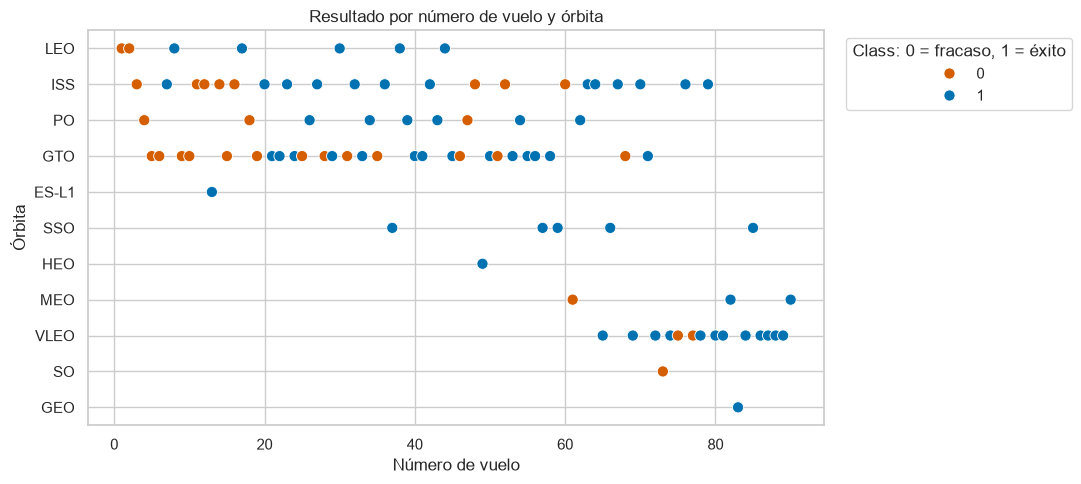

In [8]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x="FlightNumber", y="Orbit", hue="Class",
                palette={0: "#D55E00", 1: "#0072B2"}, s=65)
plt.xlabel("Número de vuelo")
plt.ylabel("Órbita")
plt.title("Resultado por número de vuelo y órbita")
plt.legend(title="Class: 0 = fracaso, 1 = éxito", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Análisis:** En LEO, los primeros vuelos incluyen fracasos y los posteriores muestran éxitos. En GTO se mezclan éxitos y fracasos durante un intervalo más amplio, aunque los vuelos finales de la muestra son mayoritariamente exitosos. El gráfico no demuestra una relación causal.

### TASK  5: Visualize the relationship between Payload and Orbit type


Similarly, we can plot the Payload vs. Orbit scatter point charts to reveal the relationship between Payload and Orbit type


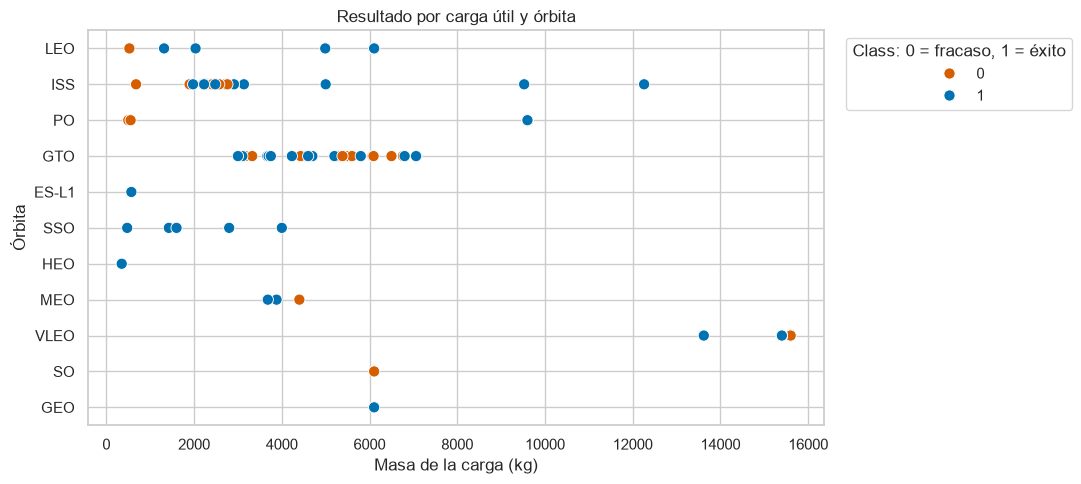

In [9]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x="PayloadMass", y="Orbit", hue="Class",
                palette={0: "#D55E00", 1: "#0072B2"}, s=65)
plt.xlabel("Masa de la carga (kg)")
plt.ylabel("Órbita")
plt.title("Resultado por carga útil y órbita")
plt.legend(title="Class: 0 = fracaso, 1 = éxito", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Análisis:** Hay aterrizajes exitosos con cargas elevadas en ISS, PO y VLEO. En GTO se observan ambos resultados con masas similares, por lo que la carga no basta para distinguirlos. Las comparaciones también dependen de la órbita y del período del lanzamiento.

### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend. 


The function will help you get the year from the date:


In [10]:
# Extraer el año sin modificar listas globales ni acumular valores al reejecutar.
def Extract_year(date):
    return pd.to_datetime(date).dt.year

year = Extract_year(df["Date"])

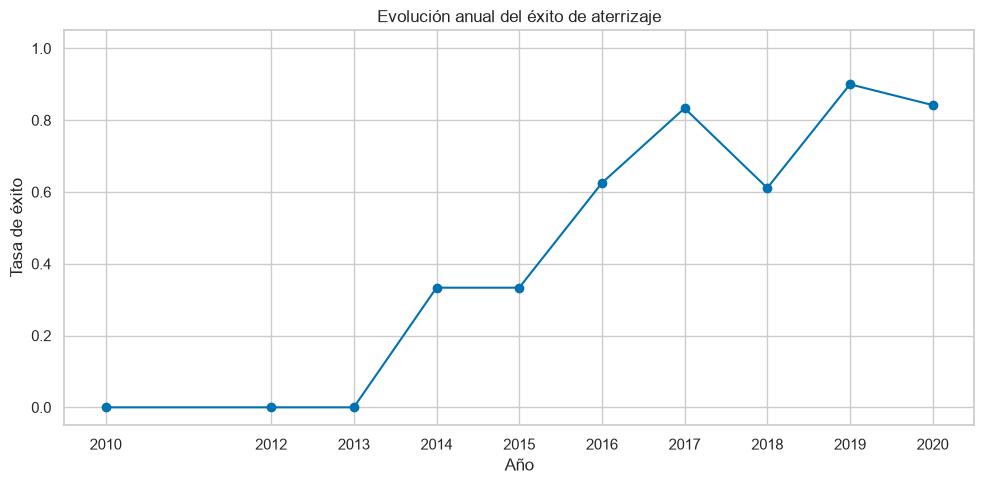

Year
2010    0.000000
2012    0.000000
2013    0.000000
2014    0.333333
2015    0.333333
2016    0.625000
2017    0.833333
2018    0.611111
2019    0.900000
2020    0.842105
Name: Class, dtype: float64

In [11]:
yearly_success = df.assign(Year=year).groupby("Year")["Class"].mean()
plt.figure(figsize=(10, 5))
plt.plot(yearly_success.index, yearly_success.values, marker="o", color="#0072B2")
plt.xticks(yearly_success.index)
plt.ylim(-0.05, 1.05)
plt.xlabel("Año")
plt.ylabel("Tasa de éxito")
plt.title("Evolución anual del éxito de aterrizaje")
plt.tight_layout()
plt.show()
yearly_success

**Análisis:** La tasa pasa del 0 % en 2013 al 33,3 % en 2014 y 2015, al 62,5 % en 2016 y al 83,3 % en 2017. Después baja al 61,1 % en 2018, sube al 90 % en 2019 y alcanza el 84,2 % en 2020. La tendencia general mejora, pero no es monótona. No hay registros de 2011 en este conjunto.

## Features Engineering 


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the future module.


In [12]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


 ### TASK  7: Create dummy variables to categorical columns


Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.


In [13]:
# La columna se llama Orbit (singular) en este conjunto de datos.
features_one_hot = pd.get_dummies(
    features, columns=["Orbit", "LaunchSite", "LandingPad", "Serial"], dtype=int
)
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,525.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,677.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,500.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,3170.000000,1,False,False,False,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers cast the entire dataframe to variable type <code>float64</code>


In [14]:
features_one_hot = features_one_hot.astype("float64")
features_one_hot.dtypes

FlightNumber    float64
PayloadMass     float64
Flights         float64
GridFins        float64
Reused          float64
                 ...   
Serial_B1056    float64
Serial_B1058    float64
Serial_B1059    float64
Serial_B1060    float64
Serial_B1062    float64
Length: 80, dtype: object

We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range. 


In [15]:
features_one_hot.to_csv('dataset_part_3.csv', index=False)
features_one_hot.shape

(90, 80)

## Authors


<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


<a href="https://www.linkedin.com/in/nayefaboutayoun/">Nayef Abou Tayoun</a> is a Data Scientist at IBM and pursuing a Master of Management in Artificial intelligence degree at Queen's University.


## Change Log


| Date (YYYY-MM-DD) | Version | Changed By | Change Description      |
| ----------------- | ------- | ---------- | ----------------------- |
| 2021-10-12        | 1.1     | Lakshmi Holla     | Modified markdown |
| 2020-09-20        | 1.0     | Joseph     | Modified Multiple Areas |
| 2020-11-10       | 1.1    | Nayef      | updating the input data |


Copyright © 2020 IBM Corporation. All rights reserved.
